# 02. MPS crime: annual, previous year and prior twelve months

Run the audit notebook `crime_housing_project_analysis.ipynb` first. This notebook reads its merged export, performs only essential integrity checks, and focuses on regression tables, figures and interpretation. All results are retained regardless of sign.

The primary panel omits job density to retain 2015; pay, hours and unemployment remain included. Set `RUN_STRICT = True` for a separate panel including job density, which removes 2015. Each panel uses a common sample across all models and categories. Current-year and previous-year original-data notebooks also share identical samples with each other. MPS comparisons share a sample across all three exposure measures.

Supplied violence in 2014-2015 is all zero and original endpoint crime counts are suspicious. Original-data results are a benchmark, not verified crime effects. MPS categories differ and its coverage excludes City of London and borough mismatches.


In [1]:
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
DATA_DIR = ROOT / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

OUT = DATA_DIR / '02_crime_mps_outputs'
OUT.mkdir(exist_ok=True)
MERGED = DATA_DIR / 'crime_housing_merged.csv.gz'
if not MERGED.is_file():
    raise FileNotFoundError('Run crime_housing_project_analysis.ipynb first.')
RUN_STRICT = False
EXPOSURES = ['annual', 'lagyear', 'prior12']
MAIN = ['mps_all', 'mps_violence', 'mps_property']
AVAILABILITY = 'mps_exposures_available'


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


In [3]:
import json
df = pd.read_csv(MERGED, low_memory=False)
manifest = json.loads((DATA_DIR / 'crime_housing_manifest.json').read_text(encoding='utf-8'))
assert len(df) == manifest['rows'] and df.transaction_id.is_unique
for flag in ['analysis_geography_ok','original_pair_available','mps_exposures_available','mps_geography_ok']:
    assert pd.api.types.is_bool_dtype(df[flag]), 'Invalid saved coverage flag: ' + flag


In [4]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
data['Nearest_Park_dist_km'] = data['Nearest_Park_dist'] / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
    LOCATION += ['dist_to_cbd','Nearest_Park_dist_km']
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})


In [5]:
CRIME_COLUMNS = []
for category in MAIN:
    for exposure in ['annual', 'lagyear', 'prior12']:
        source = category + '_' + exposure
        if data[source].dropna().lt(0).any():
            raise ValueError('Negative crime counts: ' + source)
        name = 'log1p_' + source
        data[name] = np.log1p(data[source])
        CRIME_COLUMNS.append(name)
EXPOSURE = EXPOSURES[0]


## 1. One consistent model sequence

| Model | Controls | Fixed effects |
|---|---|---|
| M1 | Property only; no crime | None |
| M2 | Property + crime | None |
| M3 | Property + crime + location + economic | None |
| M4 | Same as M3 | Local authority + year |
| M5 | Same as M3 | MSOA + year |
| M6 | Same as M3 | MSOA + year-quarter |
| M7 | Same as M3 | LSOA + year-quarter |

This final numbering differs from the earlier reconciled notebook: M3 now isolates adding observable controls. Crime timing is constant through M2-M7 within each panel; no model is chosen for its sign.

Let $z_i=\ln(1+C_i)$, $H_i$ be property controls and $W_i$ be location/economic controls. Model-specific coefficients are re-estimated at every stage:

$$\mathrm{M1}:\quad \ln P_i=\alpha+\gamma'H_i+\epsilon_i$$
$$\mathrm{M2}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\epsilon_i$$
$$\mathrm{M3}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\epsilon_i$$
$$\mathrm{M4}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_b+\tau_y+\epsilon_i$$
$$\mathrm{M5}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_m+\tau_y+\epsilon_i$$
$$\mathrm{M6}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\mu_m+\lambda_q+\epsilon_i$$
$$\mathrm{M7}:\quad \ln P_i=\alpha+\beta z_i+\gamma'H_i+\theta'W_i+\nu_l+\lambda_q+\epsilon_i$$

For current-year crime, $C_i=C_{l,y}$. For previous-year crime, $C_i=C_{l,y-1}$. Prior12 uses the twelve completed months preceding the sale month. There are no borough-year effects. Year-quarter replaces year effects, and finer area effects replace broader area effects.


In [6]:
def model_specs(include_jobdensity=False):
    economic = [c for c in ECONOMIC if include_jobdensity or c != 'jobdensity']
    full = PROPERTY + LOCATION + economic
    return [
        ('M1', None, PROPERTY, []),
        ('M2', EXPOSURE, PROPERTY, []),
        ('M3', EXPOSURE, full, []),
        ('M4', EXPOSURE, full, ['oslaua','year']),
        ('M5', EXPOSURE, full, ['msoa11','year']),
        ('M6', EXPOSURE, full, ['msoa11','yearquarter']),
        ('M7', EXPOSURE, full, ['lsoacode','yearquarter']),
    ]


In [7]:
def make_sample(include_jobdensity):
    full = model_specs(include_jobdensity)[-1][2]
    required = ['lnprice','lsoacode','msoa11','oslaua','year','yearquarter'] + full + CRIME_COLUMNS
    valid = data[required].replace('', np.nan).notna().all(axis=1)
    valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
    valid &= data.analysis_geography_ok & data[AVAILABILITY]
    return data.loc[valid].copy()
sample = make_sample(False)
print('Primary sample:',len(sample),'sales;',sample.lsoacode.nunique(),'LSOA clusters')
table(sample.groupby('year').size().to_frame('sales'), 'sample_by_year')


Primary sample: 338347 sales; 4647 LSOA clusters


,sales
year,
2012,85375
2013,99429
2014,108207
2015,45336


## 2. Estimation helpers

The following cells define absorption and LSOA-clustered inference. Expandable coefficient tables include every identified control. Absorbed/collinear controls are listed. Fixed-effects R-squared is within R-squared; compare it with the same definition only. The estimator uses a cluster-count correction, without a further absorbed-effect degrees-of-freedom correction. It does not report intercepts or individual fixed effects.


In [8]:
from linearmodels.iv import AbsorbingLS
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    """Estimate OLS with high-dimensional fixed effects using linearmodels."""
    names = ([crime] if crime is not None else []) + controls
    x = data[names].astype(float).copy()
    y = data.lnprice.astype(float).copy()
    scale = x.std(axis=0).to_numpy().copy()
    scale[scale < 1e-14] = 1
    x_scaled = x / scale
    if fixed_effects:
        absorbed = pd.DataFrame(
            {c: pd.Categorical(data[c]) for c in fixed_effects}, index=data.index
        )
    else:
        absorbed = None
        y = y - y.mean()
        x_scaled = x_scaled - x_scaled.mean(axis=0)
    fit = AbsorbingLS(
        y, x_scaled, absorb=absorbed, drop_absorbed=True
    ).fit(cov_type='clustered', clusters=data[cluster], debiased=True)
    group = pd.factorize(data[cluster], sort=False)[0]
    G = int(group.max() + 1)
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    identified = list(fit.params.index)
    if crime is not None and crime not in identified:
        raise ValueError('Crime has no identifying variation in this specification')
    estimates = fit.params.to_numpy() / scale[[names.index(c) for c in identified]]
    se = fit.std_errors.to_numpy() / scale[[names.index(c) for c in identified]]
    critical = stats.t.ppf(0.975, G - 1)
    j = identified.index(crime) if crime is not None else 0
    result = {
        'N': len(data), 'clusters': G,
        'beta': estimates[j] if crime is not None else np.nan,
        'se': se[j] if crime is not None else np.nan,
        'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1) if crime is not None else np.nan,
        'ci_low': estimates[j] - critical * se[j] if crime is not None else np.nan,
        'ci_high': estimates[j] + critical * se[j] if crime is not None else np.nan,
        'r2': fit.rsquared, 'r2_type': 'within' if fixed_effects else 'ordinary',
        'crime_residual_sd': x_scaled.iloc[:, names.index(crime)].std() * scale[names.index(crime)] if crime is not None else np.nan,
        'iterations': 0,
        'absorbed_or_collinear': '; '.join(c for c in names if c not in identified),
        'fixed_effects': '; '.join(fixed_effects),
    }
    coefficients = pd.DataFrame({
        'variable': identified, 'beta': estimates, 'se': se,
    })
    return (result, coefficients)



In [9]:
def estimate_specs(sample, panel, specs):
    rows, coefficients = [], []
    for model, exposure, controls, effects in specs:
        prepared = sample
        iterations = 0
        if effects:
            exposures = [exposure or 'annual']
            crime_columns = ['log1p_'+c+'_'+e for c in MAIN for e in exposures]
            columns = ['lnprice']+crime_columns+controls
            matrix = sample[columns].to_numpy(dtype=float,copy=True)
            scale = matrix.std(axis=0);scale[scale<1e-14]=1
            projected,iterations = absorb(matrix/scale,[sample[c] for c in effects])
            projected[:,projected.std(axis=0)<1e-7]=0
            prepared=sample.copy();prepared[columns]=projected*scale
        for category in MAIN if exposure is not None else ['no crime']:
            regressor = 'log1p_'+category+'_'+exposure if exposure is not None else None
            r,b = fit_absorbed(prepared,regressor,controls,[])
            r.update(fixed_effects='; '.join(effects),
                     r2_type='within' if effects else 'ordinary',iterations=iterations)
            rows.append(dict(panel=panel,model=model,crime=category,
                             crime_exposure=exposure or 'none',location_mode=LOCATION_MODE,**r))
            coefficients.append(b.assign(panel=panel,model=model,crime=category))
    results = pd.DataFrame(rows)
    results.to_csv(OUT/(panel+'_models.csv'),index=False)
    pd.concat(coefficients).to_csv(OUT/(panel+'_all_coefficients.csv'),index=False)
    print(f'{panel}: {len(results)} regressions on {len(sample):,} identical transactions.')
    return results


In [10]:
def plot_panel(results, filename):
    fig, axes = plt.subplots(1, 3, figsize=(15,4), sharex=True)
    order = ['M2','M3','M4','M5','M6','M7']
    for ax, category in zip(axes, MAIN):
        b = results.loc[results.crime.eq(category)].set_index('model').reindex(order)
        x = np.arange(len(order))
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=3)
        ax.axhline(0,color='grey',linestyle='--')
        ax.set_xticks(x,order);ax.set_title(category);ax.set_ylabel('Crime coefficient and 95% CI')
    fig.tight_layout();fig.savefig(OUT / (filename + '.png'),dpi=160);plt.show()

def interpret_results(results, panel):
    b=results.loc[results.model.eq('M7')].copy()
    b['evidence'] = np.where(b.ci_high.lt(0),'Negative; CI excludes zero',np.where(b.ci_low.gt(0),'Positive; CI excludes zero','CI includes zero'))
    table(b[['crime','N','beta','ci_low','ci_high','p','evidence']], panel + '_m7_interpretation')
    print('M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.')
    print('Compare coefficient size and confidence intervals, not just significance stars.')


## 3. Regressions, coefficient plots and individual control tables


In [11]:
all_results=[]
for EXPOSURE in EXPOSURES:
    panel = 'primary_' + EXPOSURE
    print('Exposure:', EXPOSURE)
    results = estimate_specs(sample, panel, model_specs(False))
    results['exposure_label'] = EXPOSURE
    all_results.append(results)
    table(results.loc[results.model.ne('M1'),['model','crime','N','beta','se','ci_low','ci_high','p','r2','r2_type']], panel + '_summary')
    show_models(results, panel + '_models', panel + '_all_coefficients.csv')
    interpret_results(results, panel)
combined = pd.concat(all_results, ignore_index=True)
combined.to_csv(OUT / 'combined_primary_models.csv', index=False)
assert combined.N.nunique() == 1


Exposure: annual
primary_annual: 19 regressions on 338,347 identical transactions.


,model,crime,N,beta,se,ci_low,ci_high,p,r2,r2_type
1,M2,mps_all,338347,0.1248,0.0146,0.0962,0.1535,1.7513e-17,0.0887,ordinary
2,M2,mps_violence,338347,-0.0879,0.0124,-0.1123,-0.0635,1.9208e-12,0.0837,ordinary
3,M2,mps_property,338347,0.1998,0.0135,0.1734,0.2262,1.3729e-48,0.1135,ordinary
4,M3,mps_all,338347,-0.0337,0.0099,-0.0532,-0.0142,6.9332e-04,0.5161,ordinary
5,M3,mps_violence,338347,-0.1347,0.0077,-0.1498,-0.1197,9.0898e-67,0.5366,ordinary
6,M3,mps_property,338347,0.0364,0.0087,0.0193,0.0535,3.0093e-05,0.5163,ordinary
7,M4,mps_all,338347,-0.0427,0.0087,-0.0597,-0.0257,8.9099e-07,0.4047,within
8,M4,mps_violence,338347,-0.1383,0.0075,-0.1530,-0.1237,3.4808e-74,0.4312,within
9,M4,mps_property,338347,0.0205,0.0076,0.0056,0.0355,7.1478e-03,0.4032,within
10,M5,mps_all,338347,-0.0103,0.0050,-0.0202,-0.0005,3.9625e-02,0.4349,within


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.6112,0.0271,22.53,0.5581 to 0.6644,<0.001
Semi-detached (relative to flat),0.1706,0.0230,7.42,0.1255 to 0.2157,<0.001
Terraced (relative to flat),0.1421,0.0222,6.40,0.0986 to 0.1856,<0.001
Freehold,0.0962,0.0219,4.39,0.0532 to 0.1392,<0.001
New build,0.0887,0.0278,3.19,0.0341 to 0.1433,0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all annual),0.1248,0.0146,8.54,0.0962 to 0.1535,<0.001
Detached (relative to flat),0.6699,0.0272,24.64,0.6166 to 0.7232,<0.001
Semi-detached (relative to flat),0.2138,0.0229,9.34,0.1689 to 0.2587,<0.001
Terraced (relative to flat),0.1554,0.0220,7.06,0.1122 to 0.1985,<0.001


,crime,N,beta,ci_low,ci_high,p,evidence
16,mps_all,338347,0.0057,-0.0045,0.0159,0.2705,CI includes zero
17,mps_violence,338347,0.0006,-0.0049,0.0062,0.8232,CI includes zero
18,mps_property,338347,0.0074,-0.0012,0.0160,0.0914,CI includes zero


M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.
Compare coefficient size and confidence intervals, not just significance stars.
Exposure: lagyear
primary_lagyear: 19 regressions on 338,347 identical transactions.


...

M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.
Compare coefficient size and confidence intervals, not just significance stars.
Exposure: prior12
primary_prior12: 19 regressions on 338,347 identical transactions.


,model,crime,N,beta,se,ci_low,ci_high,p,r2,r2_type
1,M2,mps_all,338347,0.1234,0.0146,9.4760e-02,0.1521,4.3193e-17,0.0885,ordinary
2,M2,mps_violence,338347,-0.0965,0.0126,-1.2114e-01,-0.0719,1.8315e-14,0.0857,ordinary
3,M2,mps_property,338347,0.1963,0.0136,1.6968e-01,0.2229,1.8338e-46,0.1120,ordinary
4,M3,mps_all,338347,-0.0326,0.0100,-5.2163e-02,-0.0131,1.0634e-03,0.5160,ordinary
5,M3,mps_violence,338347,-0.1371,0.0078,-1.5232e-01,-0.1218,2.5110e-67,0.5372,ordinary
6,M3,mps_property,338347,0.0349,0.0087,1.7783e-02,0.0521,6.6120e-05,0.5162,ordinary
7,M4,mps_all,338347,-0.0419,0.0087,-5.8878e-02,-0.0249,1.4284e-06,0.4047,within
8,M4,mps_violence,338347,-0.1342,0.0073,-1.4848e-01,-0.1200,1.9495e-73,0.4303,within
9,M4,mps_property,338347,0.0187,0.0077,3.7258e-03,0.0337,1.4431e-02,0.4031,within
10,M5,mps_all,338347,-0.0113,0.0051,-2.1242e-02,-0.0014,2.5701e-02,0.4349,within


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Detached (relative to flat),0.6112,0.0271,22.53,0.5581 to 0.6644,<0.001
Semi-detached (relative to flat),0.1706,0.0230,7.42,0.1255 to 0.2157,<0.001
Terraced (relative to flat),0.1421,0.0222,6.40,0.0986 to 0.1856,<0.001
Freehold,0.0962,0.0219,4.39,0.0532 to 0.1392,<0.001
New build,0.0887,0.0278,3.19,0.0341 to 0.1433,0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all prior12),0.1234,0.0146,8.44,0.0948 to 0.1521,<0.001
Detached (relative to flat),0.6680,0.0272,24.58,0.6147 to 0.7213,<0.001
Semi-detached (relative to flat),0.2128,0.0229,9.30,0.1679 to 0.2577,<0.001
Terraced (relative to flat),0.1548,0.0220,7.03,0.1116 to 0.1979,<0.001


,crime,N,beta,ci_low,ci_high,p,evidence
16,mps_all,338347,-0.0006,-0.0125,0.0113,0.9229,CI includes zero
17,mps_violence,338347,0.0002,-0.0056,0.0060,0.9425,CI includes zero
18,mps_property,338347,-0.0002,-0.0094,0.0090,0.9719,CI includes zero


M7 uses within-LSOA comparisons with year-quarter effects. No sign establishes causality.
Compare coefficient size and confidence intervals, not just significance stars.


## 4. Timing comparison and uncertainty

Only the MPS notebook varies timing within this notebook. Comparisons retain exactly the same sales, controls and clustering. Do not interpret a difference in significance as a statistically tested difference in coefficients.


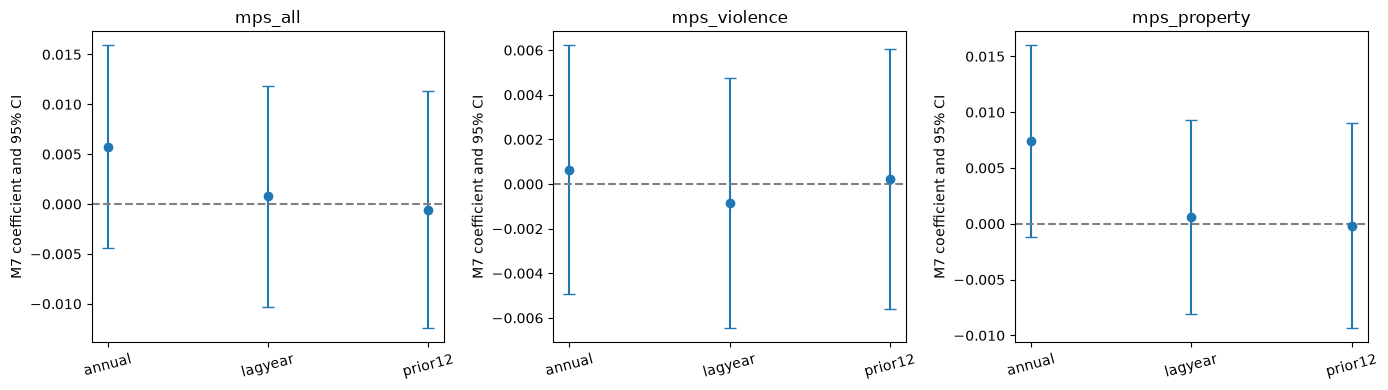

In [12]:
if len(EXPOSURES) > 1:
    fig, axes = plt.subplots(1,3,figsize=(14,4))
    for ax, category in zip(axes, MAIN):
        b = combined.loc[combined.model.eq('M7') & combined.crime.eq(category)].set_index('exposure_label').reindex(EXPOSURES)
        x=np.arange(len(EXPOSURES))
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=4)
        ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(x,EXPOSURES,rotation=15)
        ax.set_title(category);ax.set_ylabel('M7 coefficient and 95% CI')
    fig.tight_layout();fig.savefig(OUT / 'm7_timing_comparison.png',dpi=160);plt.show()
else:
    print('This notebook keeps crime timing fixed:', EXPOSURES[0])


## 5. Optional strict panel with job density


In [13]:
if RUN_STRICT:
    strict = make_sample(True)
    for EXPOSURE in EXPOSURES:
        panel='strict_' + EXPOSURE
        results=estimate_specs(strict,panel,model_specs(True))
        plot_panel(results,panel + '_coefficient_path')
        show_models(results,panel + '_models',panel + '_all_coefficients.csv')
        interpret_results(results,panel)
else:
    print('Strict panel skipped. Set RUN_STRICT=True above to estimate it.')


Strict panel skipped. Set RUN_STRICT=True above to estimate it.


## 6. Economic interpretation and report guidance

These are adjusted associations. Fixed effects remove persistent area differences and common time shocks, but not unobserved local changes, reverse causality, changing housing quality or reporting. Lagging improves chronological order without establishing exogeneity.

With $\ln(1+C)$, the exact model-implied price change for a change from $C$ to $C'$ is $100[\exp\{\hat\beta\ln((1+C')/(1+C))\}-1]$. The crime elasticity at count $C$ is $\hat\beta C/(1+C)$, not exactly $\hat\beta$. Property dummy coefficients correspond to $100(e^\gamma-1)$ percent differences; they are not elasticities.

A confidence interval including zero does not prove no effect. Report the full sequential coefficient path and sensitivity to geography and timing. Any willingness-to-pay calculation is an illustrative capitalised association under the identifying assumptions, not an annual payment or the full social cost of crime. Do not select a specification for a negative sign.


## 7. Findings from the saved run

The primary panel uses 338,347 transactions. The following notes describe the saved run; rerun-generated interpretation tables above remain authoritative if inputs change.

**annual crime, M7 (LSOA + year-quarter):**

- all: coefficient +0.00574; 95% CI [-0.00442, +0.01591], p=0.268. The interval includes zero.
- violence: coefficient +0.00067; 95% CI [-0.00490, +0.00623], p=0.815. The interval includes zero.
- property: coefficient +0.00739; 95% CI [-0.00118, +0.01597], p=0.0909. The interval includes zero.

**lagyear crime, M7 (LSOA + year-quarter):**

- all: coefficient +0.00083; 95% CI [-0.01027, +0.01192], p=0.884. The interval includes zero.
- violence: coefficient -0.00086; 95% CI [-0.00647, +0.00475], p=0.763. The interval includes zero.
- property: coefficient +0.00060; 95% CI [-0.00809, +0.00929], p=0.892. The interval includes zero.

**prior12 crime, M7 (LSOA + year-quarter):**

- all: coefficient -0.00041; 95% CI [-0.01226, +0.01144], p=0.945. The interval includes zero.
- violence: coefficient +0.00026; 95% CI [-0.00558, +0.00610], p=0.931. The interval includes zero.
- property: coefficient -0.00011; 95% CI [-0.00929, +0.00908], p=0.982. The interval includes zero.

All nine M7 confidence intervals across annual, lagyear and prior12 crime include zero. The negative MSOA violence association does not persist with finer LSOA effects. These estimates do not establish a consistent negative causal relationship; report the full geographical and timing sensitivity.


## 8. MPS crime: annual, previous-year and prior12: beta values from M2 to M7

Each labelled point is the estimated crime coefficient itself. Below the dashed zero line means a negative estimate; above it means positive. Confidence intervals crossing zero mean the estimate is not statistically distinguishable from zero at the 5% level. M1 is omitted because it contains no crime coefficient.

M2 adds crime; M3 adds location/economic controls; M4 adds local-authority and year effects; M5 uses MSOA; M6 uses year-quarter; M7 uses LSOA. Each MPS exposure has its own row, so every actual beta is readable.


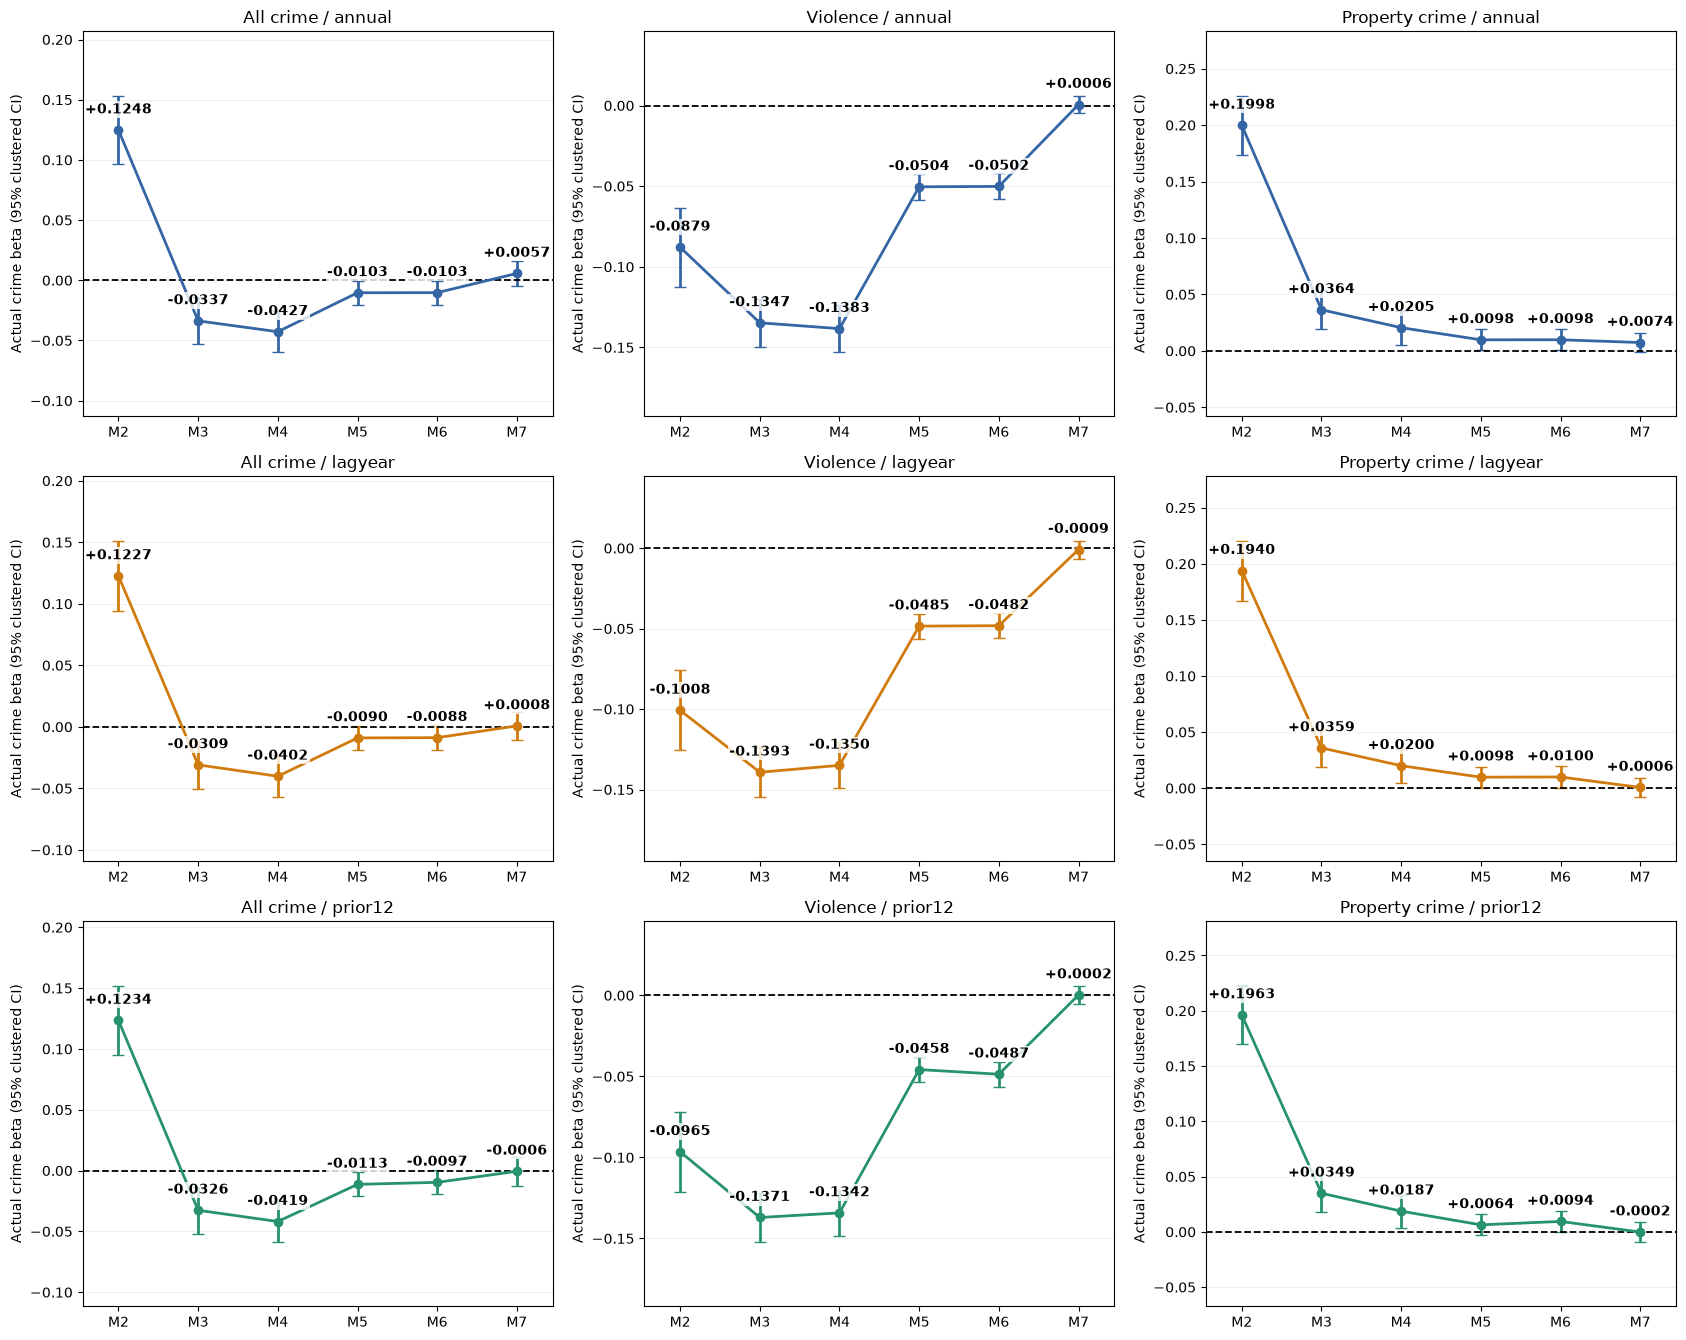

,exposure_label,model,crime,beta,ci_low,ci_high,p
1,annual,M2,mps_all,0.1248,0.0962,0.1535,1.7513e-17
2,annual,M2,mps_violence,-0.0879,-0.1123,-0.0635,1.9208e-12
3,annual,M2,mps_property,0.1998,0.1734,0.2262,1.3729e-48
4,annual,M3,mps_all,-0.0337,-0.0532,-0.0142,6.9332e-04
5,annual,M3,mps_violence,-0.1347,-0.1498,-0.1197,9.0898e-67
6,annual,M3,mps_property,0.0364,0.0193,0.0535,3.0093e-05
7,annual,M4,mps_all,-0.0427,-0.0597,-0.0257,8.9099e-07
8,annual,M4,mps_violence,-0.1383,-0.1530,-0.1237,3.4808e-74
9,annual,M4,mps_property,0.0205,0.0056,0.0355,7.1478e-03
10,annual,M5,mps_all,-0.0103,-0.0202,-0.0005,3.9625e-02


Showing 20 of 54 rows; the complete table is saved as actual_beta_values_sequence.csv.


In [14]:
MODEL_ORDER = ['M2','M3','M4','M5','M6','M7']
CRIME_NAMES = dict(zip(MAIN, ['All crime','Violence','Property crime']))
COLORS = {'annual':'#3465a4','lagyear':'#d17b0f','prior12':'#27936c'}
combined = pd.read_csv(OUT / 'combined_primary_models.csv')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=170, bbox_inches='tight')
    plt.show()
fig, axes = plt.subplots(len(EXPOSURES),3,figsize=(17,4.5*len(EXPOSURES)),squeeze=False)
for i, exposure in enumerate(EXPOSURES):
    for j, category in enumerate(MAIN):
        ax=axes[i,j]
        b=combined.loc[combined.crime.eq(category)&combined.exposure_label.eq(exposure)].set_index('model').reindex(MODEL_ORDER)
        x=np.arange(6)
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o-',capsize=4,color=COLORS[exposure],linewidth=2)
        ax.axhline(0,color='black',linestyle='--',linewidth=1.3)
        for k, row in enumerate(b.itertuples()):
            ax.annotate(f'{row.beta:+.4f}',(k,row.beta),xytext=(0,12),textcoords='offset points',ha='center',fontsize=10,fontweight='bold',bbox=dict(facecolor='white',edgecolor='none',alpha=.8,pad=1))
        ax.set_xticks(x,MODEL_ORDER);ax.set_xlim(-.45,5.45)
        ax.margins(y=.25);ax.set_title(CRIME_NAMES[category]+' / '+exposure)
        ax.set_ylabel('Actual crime beta (95% clustered CI)')
        ax.grid(axis='y',alpha=.2)
save_figure(fig,'actual_beta_values_sequence')
table(combined.loc[combined.model.ne('M1'),['exposure_label','model','crime','beta','ci_low','ci_high','p']], 'actual_beta_values_sequence')

### 8.1 Additional view: change in beta between models

The existing coefficient-path figure shows levels and clustered confidence intervals. The next figure shows the change from the preceding model: M3 adds observable location/economic controls; M4 adds local-authority and year effects; M5 uses MSOA; M6 uses year-quarter; M7 uses LSOA. M2 is the starting crime model because M1 contains no crime.

These differences are descriptive. They are not significance tests: estimates from the same sales are correlated, and a valid difference test would require their joint covariance. A large change can identify sensitivity to an addition, but does not establish that endogeneity has been solved.


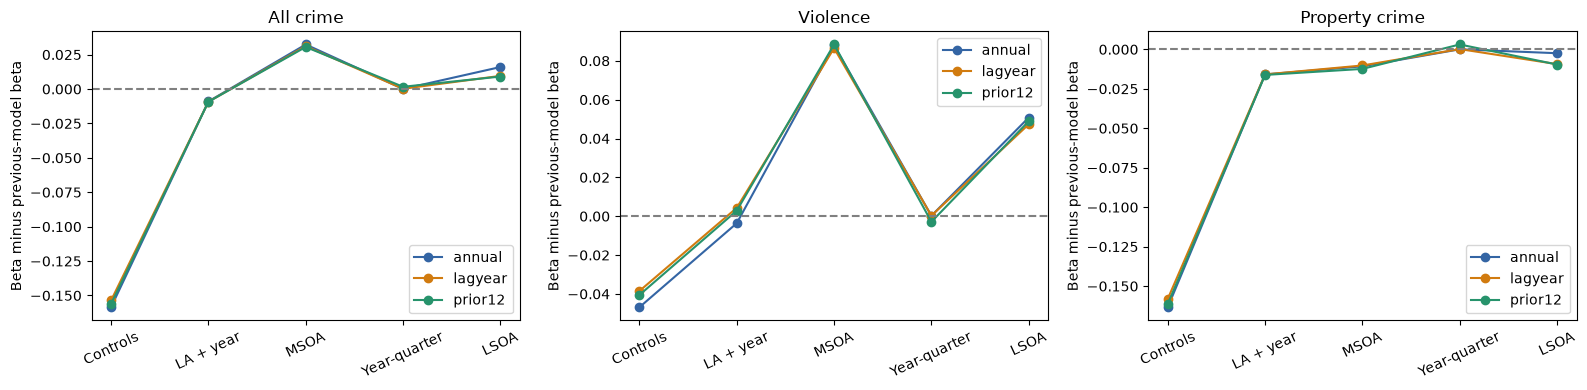

,crime,exposure,model,beta_change
0,mps_all,annual,M3,-1.5854e-01
1,mps_all,annual,M4,-9.0192e-03
2,mps_all,annual,M5,3.2382e-02
3,mps_all,annual,M6,7.3943e-05
4,mps_all,annual,M7,1.5983e-02
5,mps_all,lagyear,M3,-1.5360e-01
6,mps_all,lagyear,M4,-9.2448e-03
7,mps_all,lagyear,M5,3.1164e-02
8,mps_all,lagyear,M6,1.9260e-04
9,mps_all,lagyear,M7,9.5680e-03


Showing 20 of 45 rows; the complete table is saved as sequential_beta_changes.csv.
Largest absolute beta changes (descriptive, not causal):


,crime,exposure,model,beta_change
0,mps_all,annual,M3,-0.1585
5,mps_all,lagyear,M3,-0.1536
10,mps_all,prior12,M3,-0.1561
30,mps_property,annual,M3,-0.1634
35,mps_property,lagyear,M3,-0.1581
40,mps_property,prior12,M3,-0.1613
17,mps_violence,annual,M5,0.0880
22,mps_violence,lagyear,M5,0.0865
27,mps_violence,prior12,M5,0.0884


In [15]:
MODEL_ORDER = ['M2','M3','M4','M5','M6','M7']
ADDITIONS = ['Controls','LA + year','MSOA','Year-quarter','LSOA']
CRIME_NAMES = dict(zip(MAIN, ['All crime','Violence','Property crime']))
COLORS = {'annual':'#3465a4','lagyear':'#d17b0f','prior12':'#27936c'}
combined = pd.read_csv(OUT / 'combined_primary_models.csv')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=170, bbox_inches='tight')
    plt.show()
fig, axes = plt.subplots(1,3,figsize=(16,4))
changes=[]
for ax, category in zip(axes,MAIN):
    for exposure in EXPOSURES:
        b=combined.loc[combined.crime.eq(category) & combined.exposure_label.eq(exposure)].set_index('model').reindex(MODEL_ORDER)
        delta=b.beta.diff().iloc[1:]
        ax.plot(np.arange(5),delta,marker='o',label=exposure,color=COLORS[exposure])
        for model,value in delta.items():
            changes.append(dict(crime=category,exposure=exposure,model=model,beta_change=value))
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(5),ADDITIONS,rotation=25)
    ax.set_title(CRIME_NAMES[category]);ax.set_ylabel('Beta minus previous-model beta');ax.legend()
save_figure(fig,'sequential_beta_changes')
changes=pd.DataFrame(changes)
table(changes,'sequential_beta_changes')
largest=changes.loc[changes.groupby(['crime','exposure']).beta_change.apply(lambda x:x.abs().idxmax())]
print('Largest absolute beta changes (descriptive, not causal):')
display(largest[['crime','exposure','model','beta_change']])


## 9. Precision and how much crime variation remains

The upper panels trace clustered standard errors. The lower panels show the standard deviation of log(1 + crime) after the stated area/time effects have been removed, before partialling out other controls. M2 and M3 therefore have the same crime variation. This is not a first-stage statistic and does not diagnose endogeneity. Finer effects narrow the variation used for estimation; a larger sample alone cannot restore variation removed by the fixed effects.


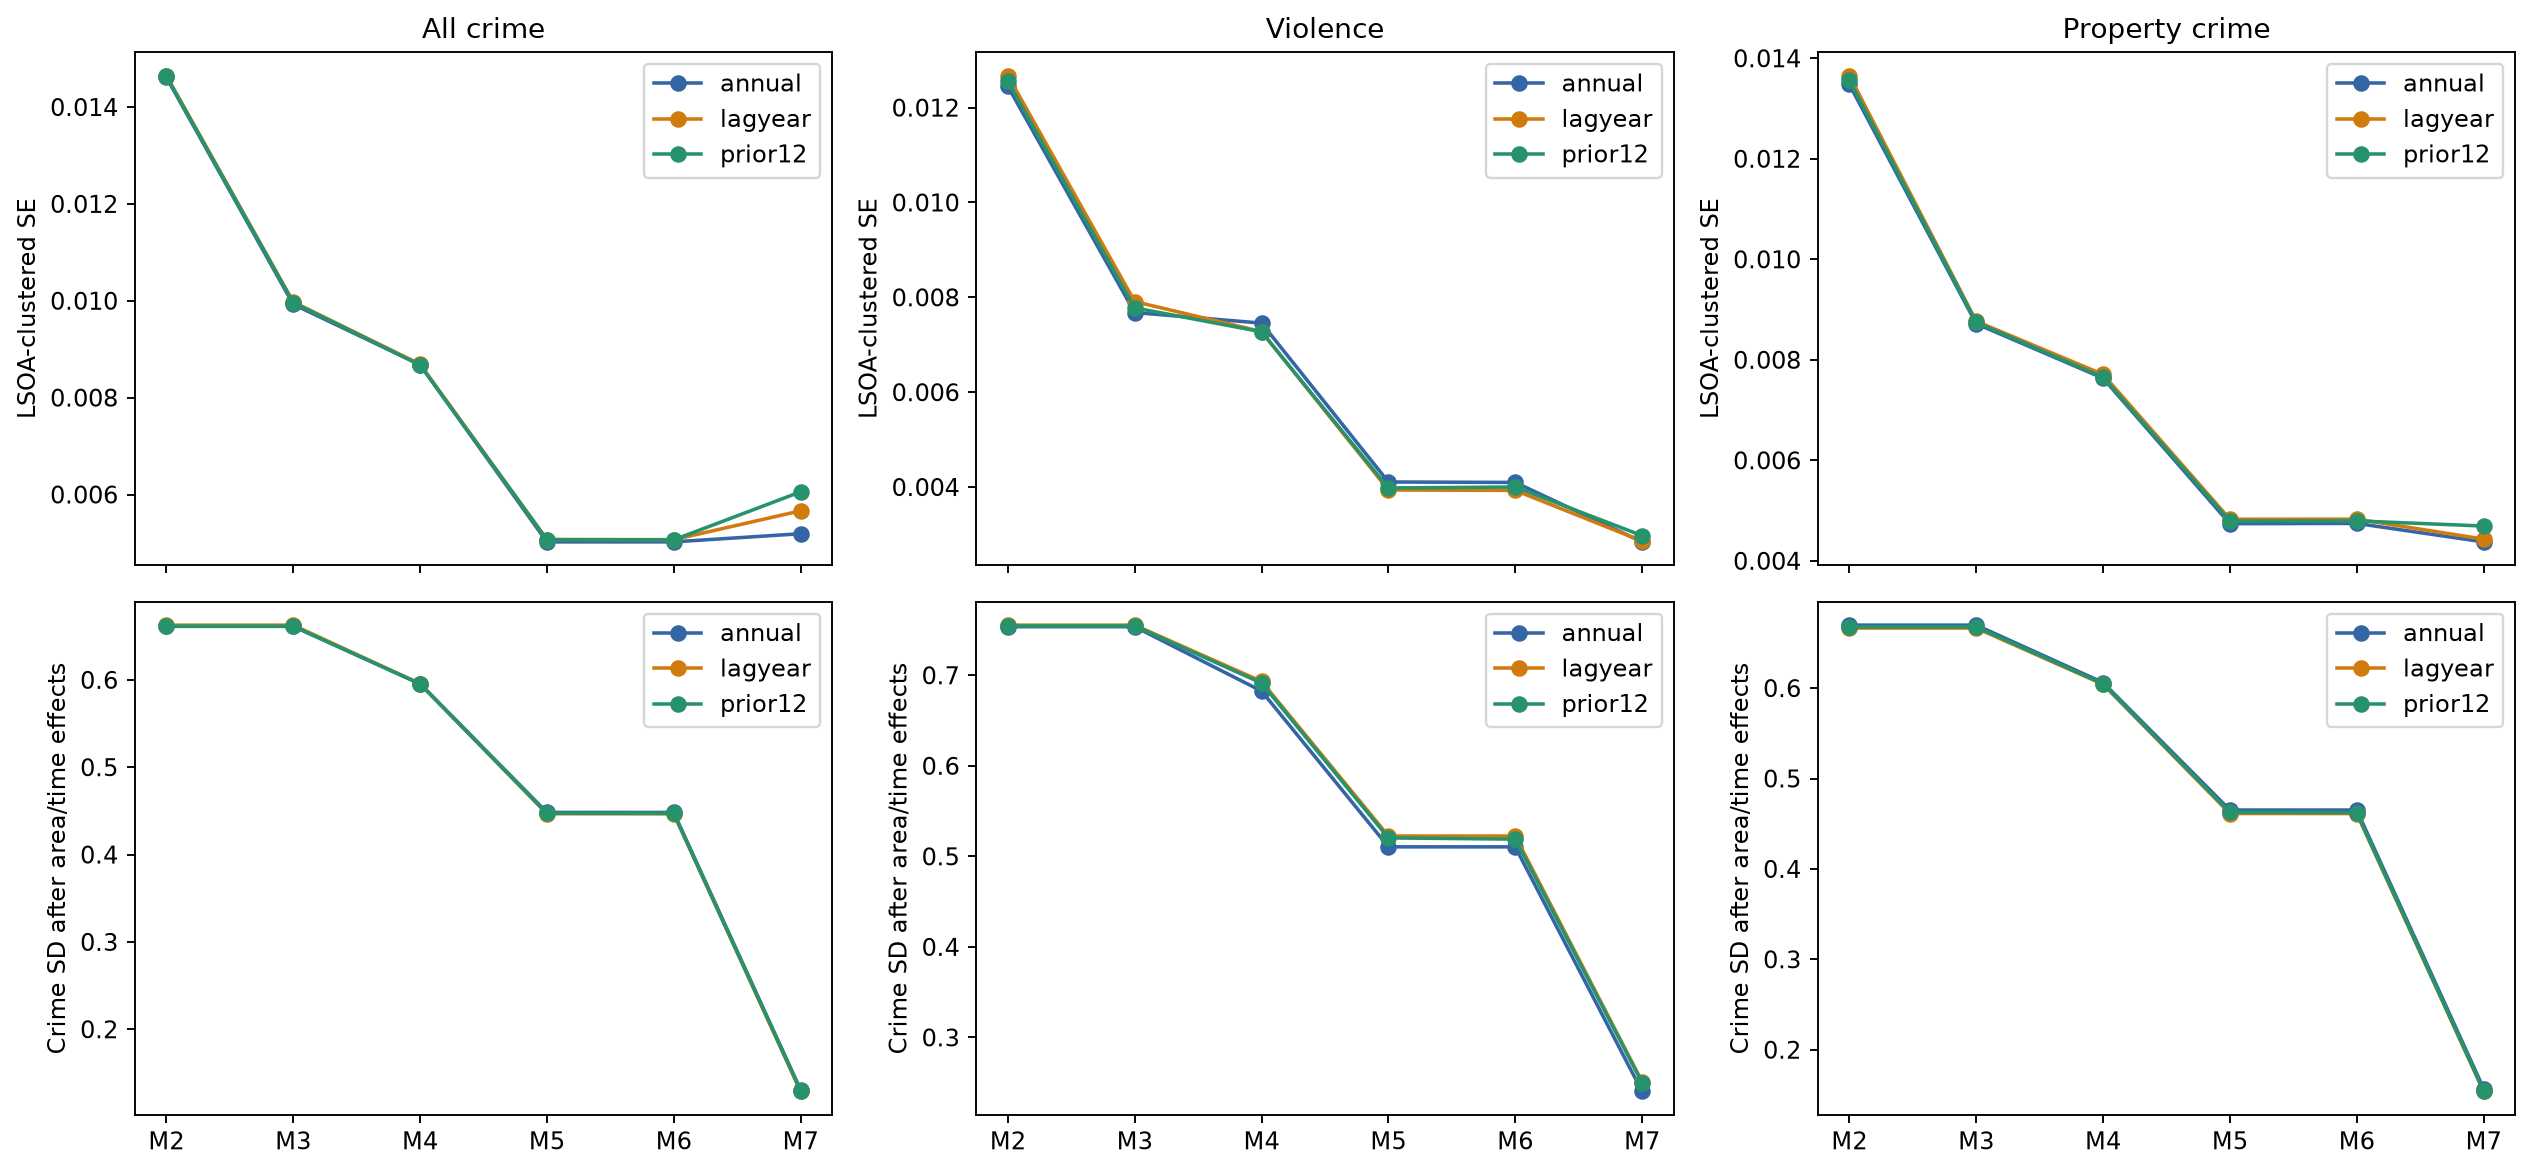

In [16]:
fig,axes=plt.subplots(2,3,figsize=(15,7),sharex=True)
for j,category in enumerate(MAIN):
    for exposure in EXPOSURES:
        b=combined.loc[combined.crime.eq(category)&combined.exposure_label.eq(exposure)].set_index('model').reindex(MODEL_ORDER)
        axes[0,j].plot(MODEL_ORDER,b.se,marker='o',color=COLORS[exposure],label=exposure)
        axes[1,j].plot(MODEL_ORDER,b.crime_residual_sd,marker='o',color=COLORS[exposure],label=exposure)
    axes[0,j].set_title(CRIME_NAMES[category]);axes[0,j].set_ylabel('LSOA-clustered SE');axes[0,j].legend()
    axes[1,j].set_ylabel('Crime SD after area/time effects');axes[1,j].legend()
save_figure(fig,'precision_and_crime_variation')


## 10. Do estimated property premiums change too?

This figure follows the property-control coefficients in the all-crime regressions, including the property-only M1 baseline. Values are transformed to exact percentage price differences, 100(exp(coefficient)-1), with transformed confidence intervals. Detached/semi-detached/terraced premiums are relative to the omitted property category; tenure and new-build indicators have their own reference categories. These are conditional associations, not the effect of physically changing a house.

This can reveal that adding area controls changes more than the crime coefficient. A property premium estimated across London can differ from one estimated within small neighbourhoods.


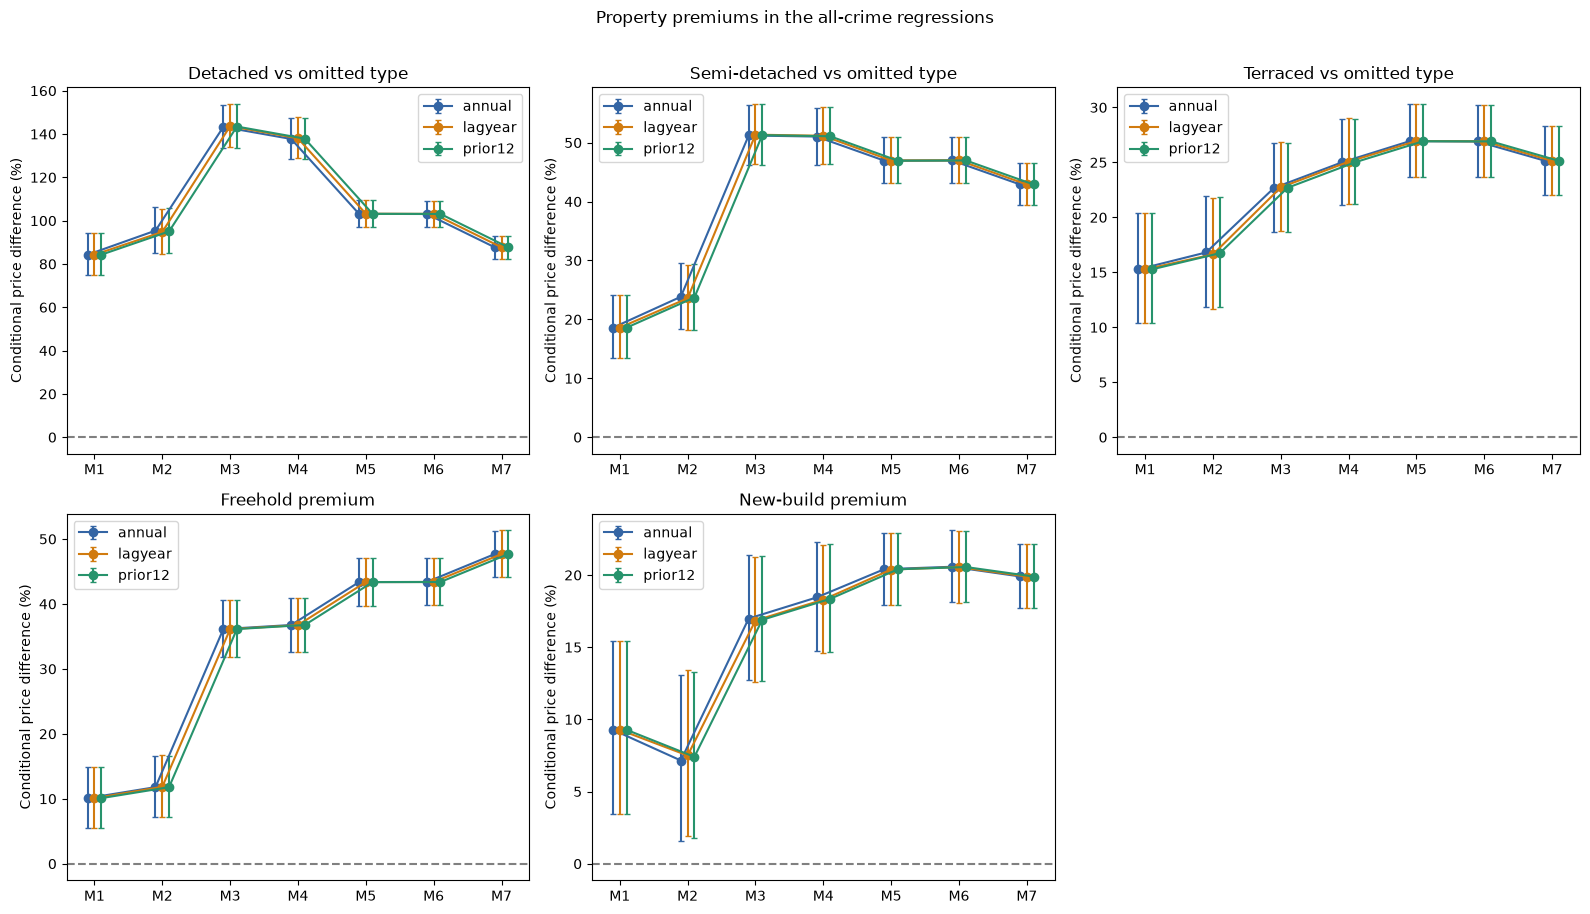

In [17]:
coefficient_panels={}
for exposure in EXPOSURES:
    coefficient_panels[exposure]=pd.read_csv(OUT / ('primary_'+exposure+'_all_coefficients.csv'))
order=['M1','M2','M3','M4','M5','M6','M7']
property_names={'detached_dum':'Detached vs omitted type','semi_d_dum':'Semi-detached vs omitted type','terrace_dum':'Terraced vs omitted type','freehold':'Freehold premium','newbuild':'New-build premium'}
fig,axes=plt.subplots(2,3,figsize=(16,9))
for ax,variable in zip(axes.flat,PROPERTY):
    for k,exposure in enumerate(EXPOSURES):
        c=coefficient_panels[exposure]
        b=c.loc[c.variable.eq(variable)&(c.crime.eq(MAIN[0])|c.model.eq('M1'))].set_index('model').reindex(order)
        center=100*np.expm1(b.beta);low=100*np.expm1(b.ci_low);high=100*np.expm1(b.ci_high)
        x=np.arange(7)+(k-(len(EXPOSURES)-1)/2)*.10
        ax.errorbar(x,center,yerr=np.vstack([center-low,high-center]),fmt='o-',capsize=2,color=COLORS[exposure],label=exposure)
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(7),order)
    ax.set_title(property_names[variable]);ax.set_ylabel('Conditional price difference (%)');ax.legend()
axes.flat[-1].axis('off')
fig.suptitle('Property premiums in the all-crime regressions',y=1.01)
save_figure(fig,'property_premium_paths')


## 11. Transport, river and economic-control paths

The next figure tracks continuous controls in the all-crime models M3-M7. Each panel has its own units and axis scale: distance coefficients are per kilometre; annual pay is per GBP 1,000; hours and unemployment retain the supplied units. These slopes should not be compared by numerical size across variables. Disappearing coefficients indicate absorption/collinearity, not a zero effect.


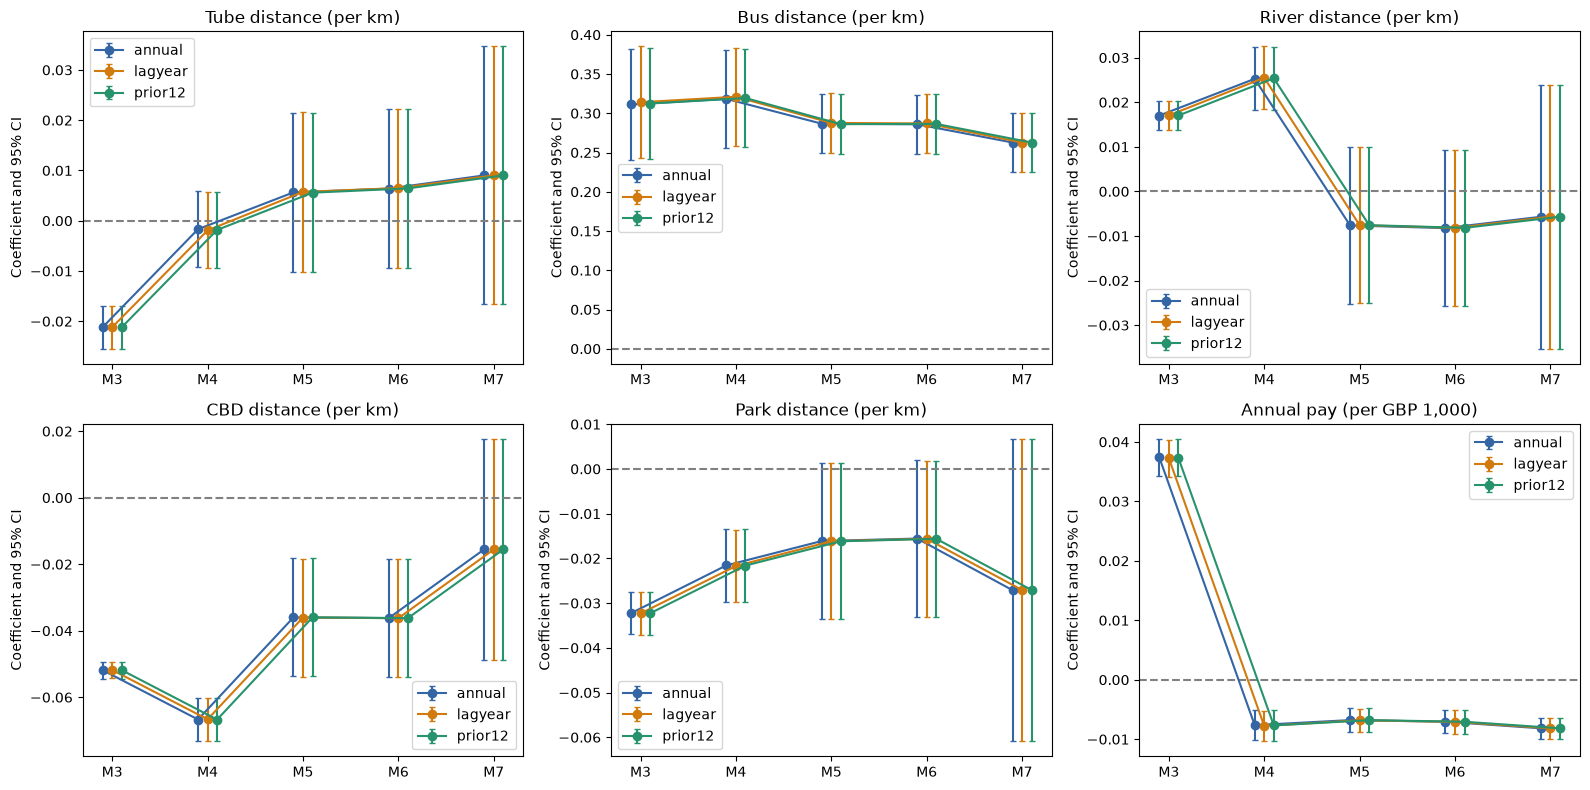

In [18]:
control_variables=LOCATION+['grossannualpay_k','hoursworked','unemployment']
control_names={'tube_distnear_km':'Tube distance (per km)','bus_distnear_km':'Bus distance (per km)','thamesriv_dist_km':'River distance (per km)','dist_to_cbd':'CBD distance (per km)','Nearest_Park_dist_km':'Park distance (per km)','grossannualpay_k':'Annual pay (per GBP 1,000)','hoursworked':'Hours worked (source units)','unemployment':'Unemployment (source units)'}
fig,axes=plt.subplots(2,3,figsize=(16,8))
for ax,variable in zip(axes.flat,control_variables):
    for k,exposure in enumerate(EXPOSURES):
        c=coefficient_panels[exposure]
        b=c.loc[c.variable.eq(variable)&c.crime.eq(MAIN[0])].set_index('model').reindex(['M3','M4','M5','M6','M7'])
        x=np.arange(5)+(k-(len(EXPOSURES)-1)/2)*.10
        ax.errorbar(x,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o-',capsize=2,label=exposure,color=COLORS[exposure])
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(5),['M3','M4','M5','M6','M7'])
    ax.set_title(control_names.get(variable,variable));ax.set_ylabel('Coefficient and 95% CI');ax.legend()
save_figure(fig,'location_economic_control_paths')


## 12. Put beta into a common economic scale

For each crime model, simulate a 10% reduction in its crime measure at every observed sale, holding controls fixed. Average the model-implied percentage price differences across the common transaction sample. For log(1 + crime), use the exact expression rather than treating beta as an exact elasticity. Zero crime remains zero.

Error bars propagate only the clustered confidence interval for beta; they do not incorporate other parameter or sampling uncertainty. This is an illustrative price association, not a causal policy benefit, welfare estimate, or London housing-stock valuation. Supplied-data measurement problems also carry into this calculation.


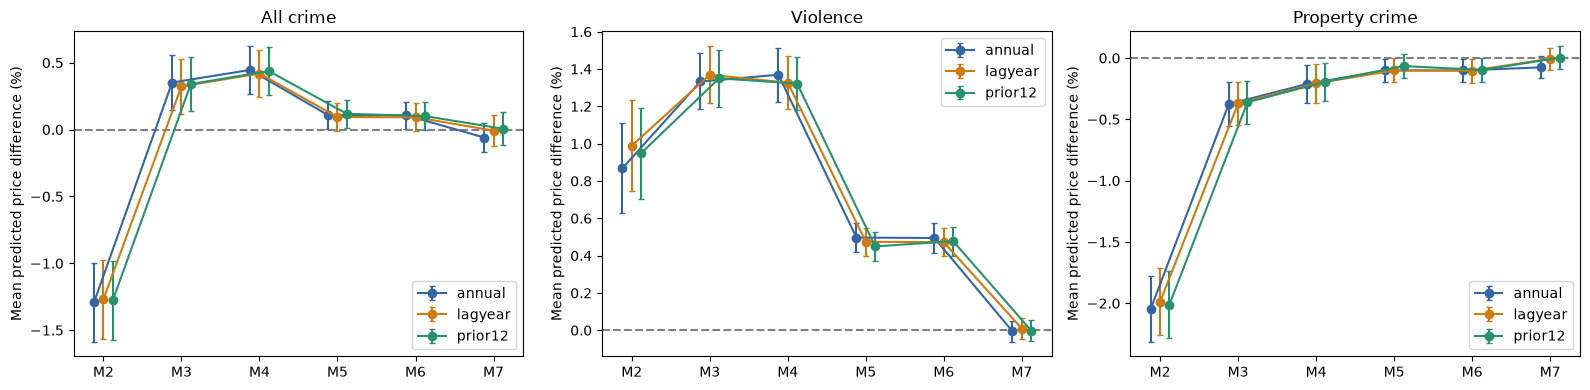

,model,crime,exposure,price_change_pct,ci_low,ci_high
0,M2,mps_all,annual,-1.2915,-1.5855,-0.9966
1,M2,mps_violence,annual,0.8675,0.6258,1.1098
2,M2,mps_property,annual,-2.0453,-2.3128,-1.7772
3,M3,mps_all,annual,0.3515,0.1483,0.5551
4,M3,mps_violence,annual,1.3331,1.1832,1.4832
5,M3,mps_property,annual,-0.3759,-0.5519,-0.1997
6,M4,mps_all,annual,0.4458,0.2679,0.6239
7,M4,mps_violence,annual,1.3691,1.2235,1.5148
8,M4,mps_property,annual,-0.2123,-0.3666,-0.0577
9,M5,mps_all,annual,0.1077,0.0051,0.2104


Showing 20 of 54 rows; the complete table is saved as ten_percent_reduction_associations.csv.


In [19]:
scenarios=[]
for row in combined.loc[combined.model.ne('M1')].itertuples():
    counts=sample[row.crime+'_'+row.exposure_label].to_numpy(float)
    log_change=np.log1p(.9*counts)-np.log1p(counts)
    def scenario(beta):
        return float(np.mean(100*np.expm1(beta*log_change)))
    endpoints=[scenario(row.ci_low),scenario(row.ci_high)]
    scenarios.append(dict(model=row.model,crime=row.crime,exposure=row.exposure_label,price_change_pct=scenario(row.beta),ci_low=min(endpoints),ci_high=max(endpoints)))
scenarios=pd.DataFrame(scenarios)
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,category in zip(axes,MAIN):
    for k,exposure in enumerate(EXPOSURES):
        b=scenarios.loc[scenarios.crime.eq(category)&scenarios.exposure.eq(exposure)].set_index('model').reindex(MODEL_ORDER)
        x=np.arange(6)+(k-(len(EXPOSURES)-1)/2)*.12
        ax.errorbar(x,b.price_change_pct,yerr=np.vstack([b.price_change_pct-b.ci_low,b.ci_high-b.price_change_pct]),fmt='o-',capsize=2,color=COLORS[exposure],label=exposure)
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(6),MODEL_ORDER)
    ax.set_title(CRIME_NAMES[category]);ax.set_ylabel('Mean predicted price difference (%)');ax.legend()
save_figure(fig,'ten_percent_crime_reduction')
table(scenarios,'ten_percent_reduction_associations')


## 13. Raw neighbourhood patterns versus adjusted estimates

Each point below represents a crime-count quantile bin of observed LSOA-periods. The horizontal coordinate is the mean crime count in that bin; the vertical coordinate is the mean of the period-level median transaction prices. Every observed LSOA-period receives equal weight. Calendar measures use LSOA-years; prior12 uses LSOA-sale-months, so those panels have different aggregation units.

These plots are descriptive: they do not control for centrality, time, property mix or other amenities. A rising raw pattern can coexist with a negative or imprecise adjusted beta. Bins with repeated crime counts can collapse, especially for supplied violence with many zeros. They are not independent causal experiments.


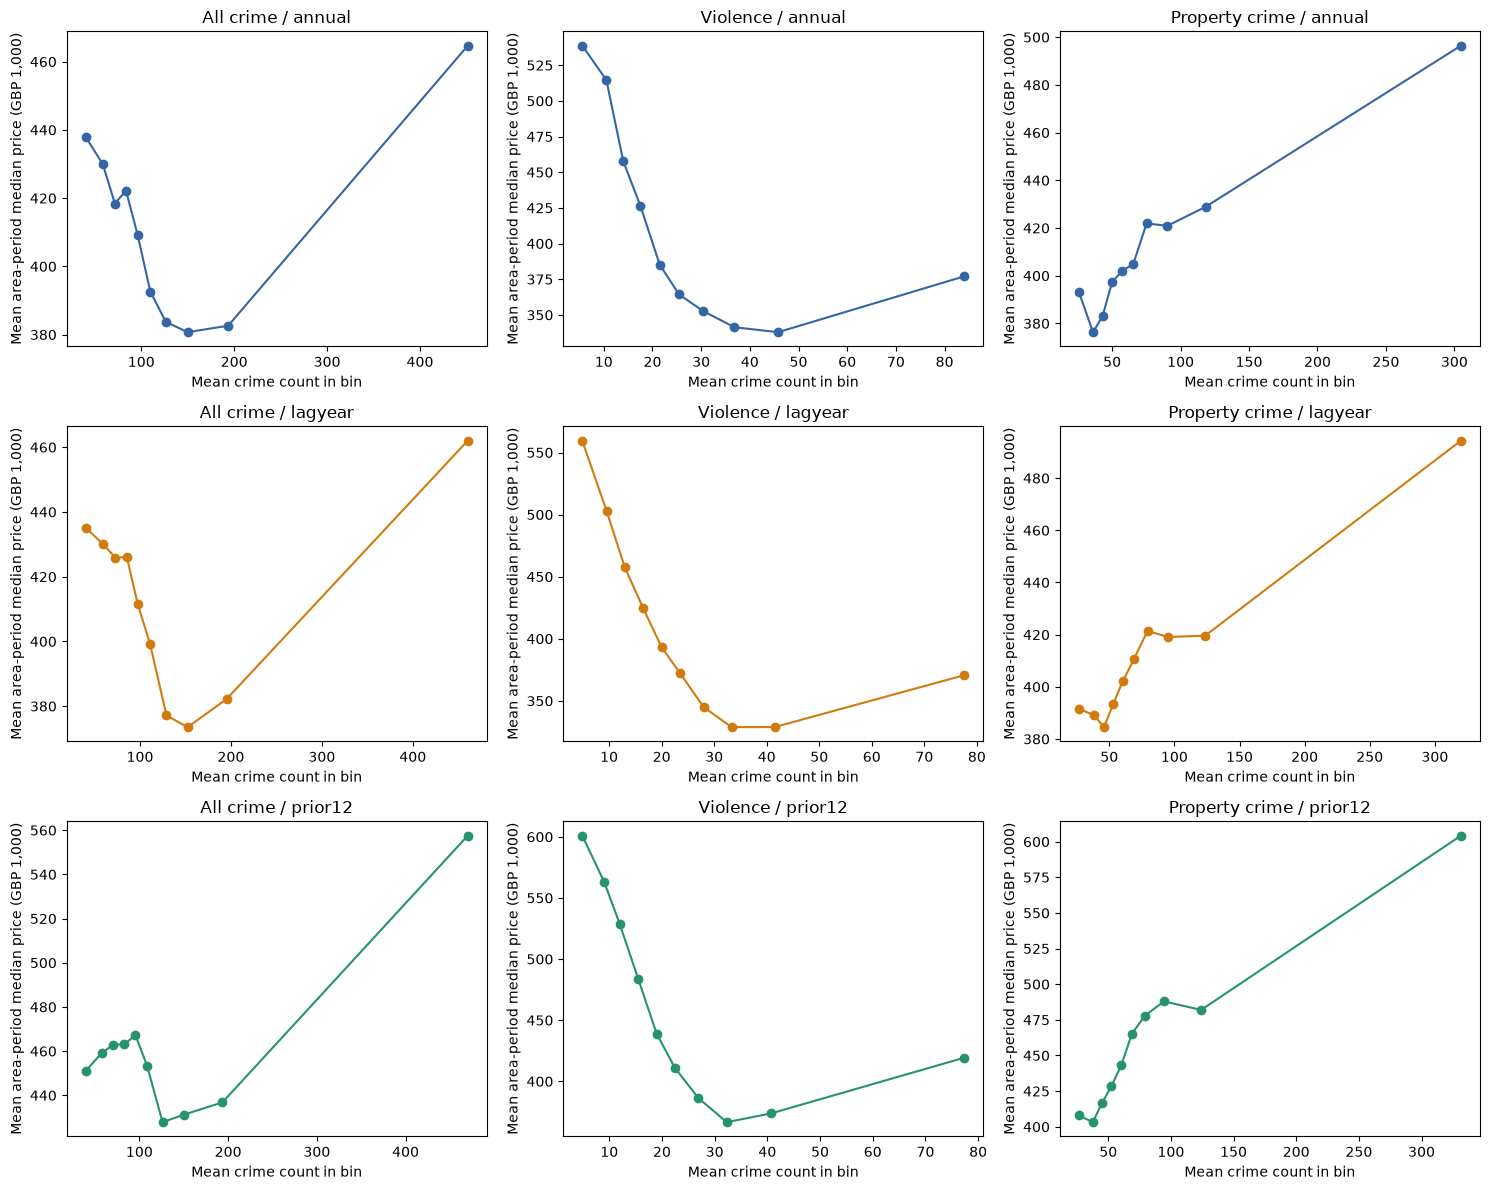

,crime,median_price,lsoa_periods,crime_category,exposure
0,40.1727,437951.4055,1969,mps_all,annual
1,58.6939,429880.5237,1833,mps_all,annual
2,71.5592,418413.6280,1758,mps_all,annual
3,83.5279,422221.7158,1830,mps_all,annual
4,95.9943,409290.4522,1924,mps_all,annual
5,109.6982,392632.3774,1799,mps_all,annual
6,126.3563,383743.0510,1754,mps_all,annual
7,149.9644,380719.6895,1852,mps_all,annual
8,193.5469,382617.4026,1823,mps_all,annual
9,451.4049,464693.4811,1825,mps_all,annual


Showing 20 of 90 rows; the complete table is saved as raw_neighbourhood_bins.csv.
Compare these raw patterns with Section 3 coefficient paths; neither is causal evidence.


In [20]:
fig,axes=plt.subplots(len(EXPOSURES),3,figsize=(15,4*len(EXPOSURES)),squeeze=False)
raw_bins=[]
for i,exposure in enumerate(EXPOSURES):
    period='sale_month' if exposure=='prior12' else 'year'
    for j,category in enumerate(MAIN):
        column=category+'_'+exposure
        area=sample.groupby(['lsoacode',period]).agg(crime=(column,'first'),median_price=('price','median')).reset_index()
        area['bin']=pd.qcut(area.crime,q=10,duplicates='drop')
        b=area.groupby('bin',observed=True).agg(crime=('crime','mean'),median_price=('median_price','mean'),lsoa_periods=('crime','size'))
        ax=axes[i,j]
        ax.plot(b.crime,b.median_price/1000,marker='o',color=COLORS[exposure])
        ax.set_title(CRIME_NAMES[category]+' / '+exposure);ax.set_xlabel('Mean crime count in bin')
        ax.set_ylabel('Mean area-period median price (GBP 1,000)')
        raw_bins.append(b.reset_index(drop=True).assign(crime_category=category,exposure=exposure))
save_figure(fig,'raw_neighbourhood_binned_patterns')
table(pd.concat(raw_bins,ignore_index=True),'raw_neighbourhood_bins')
print('Compare these raw patterns with Section 3 coefficient paths; neither is causal evidence.')


## 14. Reading the figures together: saved-run observations

For annual all crime, beta moves from +0.12484 in M2 to +0.03171 after adding observed location/economic controls in M3, then +0.00574 with LSOA and year-quarter effects in M7. This separates the control addition from geographical/time additions, rather than attributing every change to crime timing.

The SD of log(1 + all crime) used after area/time demeaning falls from 0.661 in M2 to 0.131 in M7. The clustered SE moves from 0.0146 to 0.0052. Reduced crime variation does not mechanically mean a larger SE: residual price variation, controls and within-cluster dependence also matter.

For annual violence, the move from local-authority/year effects to MSOA/year effects changes beta from -0.14730 to -0.05087; M7 is +0.00067. In the actual-beta figures, the three timing paths are similar. Geographical granularity is therefore a major source of sensitivity in this run, beyond the choice of annual versus lagged exposure. This is not a formal test that the timing effects are equal.
